In [1]:
# 1. Install
!pip -q install -U "transformers>=4.44" "peft>=0.12" "bitsandbytes>=0.43" accelerate
!pip -q install "pandas==2.2.3"
# If Colab asks to restart the session: restart, then Run all again.

In [2]:
# 2. Upload data
import os
need = [f for f in ("train.csv", "val.csv") if not os.path.exists(f)]
if need:
    from google.colab import files
    print("Upload:", need)
    files.upload()
print({f: os.path.exists(f) for f in ("train.csv", "val.csv")})

Upload: ['train.csv', 'val.csv']


Saving test.csv to test.csv
Saving train.csv to train.csv
Saving val.csv to val.csv
{'train.csv': True, 'val.csv': True}


In [3]:
# 3. Load data and model (same as the main notebook)
import re, json, math, time, random
import numpy as np, pandas as pd, torch
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, Trainer, TrainingArguments, TrainerCallback
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

MODEL_NAME, EPOCHS, LR, BATCH, LORA_R, SEED = "Qwen/Qwen2.5-3B-Instruct", 3, 2e-4, 16, 16, 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
tr = pd.read_csv("train.csv", dtype=str).fillna("")
va = pd.read_csv("val.csv", dtype=str).fillna("")
va["gold"] = va.hts.str.replace(r"\D", "", regex=True)
print(f"train {len(tr)} | val {len(va)}")

BF16 = torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if BF16 else torch.float16
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, device_map="auto", torch_dtype=DTYPE,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                           bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE))
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model = get_peft_model(model, LoraConfig(
    r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
model.print_trainable_parameters()

SYS = ("You are a US customs classification assistant. Given an engineering bill-of-materials "
       "description of a part, reply with only its 10-digit US HTS code in the form XXXX.XX.XXXX.")
def prompt(text):
    return tok.apply_chat_template([{"role": "system", "content": SYS}, {"role": "user", "content": text}],
                                   tokenize=False, add_generation_prompt=True)
END = "<|im_end|>"
def encode(text, hts):
    p = tok(prompt(text), add_special_tokens=False)["input_ids"]
    a = tok(hts + END, add_special_tokens=False)["input_ids"]
    return {"input_ids": p + a, "labels": [-100] * len(p) + a}
def collate(batch):
    L = max(len(x["input_ids"]) for x in batch)
    return {"input_ids": torch.tensor([x["input_ids"] + [tok.pad_token_id] * (L - len(x["input_ids"])) for x in batch]),
            "labels": torch.tensor([x["labels"] + [-100] * (L - len(x["labels"])) for x in batch]),
            "attention_mask": torch.tensor([[1] * len(x["input_ids"]) + [0] * (L - len(x["input_ids"])) for x in batch])}
train_data = [encode(t, h) for t, h in zip(tr.text, tr.hts)]
val_data = [encode(t, h) for t, h in zip(va.text, va.hts)]

train 2095 | val 164


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [4]:
# 4. Validation accuracy after every epoch (greedy decoding, same as evaluation)
def to_code(out):
    m = re.search(r"\d{4}\.?\d{2}\.?\d{2,4}", str(out))
    return re.sub(r"\D", "", m.group(0)) if m else re.sub(r"\D", "", str(out))[:10]

@torch.no_grad()
def predict(texts, bs=32):
    model.eval(); tok.padding_side = "left"; outs = []
    for i in range(0, len(texts), bs):
        enc = tok([prompt(t) for t in texts[i:i + bs]], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(model.device)
        g = model.generate(**enc, max_new_tokens=16, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tok.padding_side = "right"; model.train()
    return [to_code(o) for o in outs]

def val_acc():
    p = predict(va.text.tolist())
    return {f"acc@{k}": round(100 * np.mean([len(a) >= k and a[:k] == g[:k] for a, g in zip(p, va.gold)]), 1)
            for k in (4, 6, 10)}

EPOCH_ACC = []
class EpochAcc(TrainerCallback):
    def on_epoch_end(self, args, state, control, **kw):
        r = val_acc(); r["epoch"] = round(state.epoch); r["step"] = state.global_step
        EPOCH_ACC.append(r); print("validation after epoch", r)

In [5]:
# 5. Train, evaluating validation loss every 20 steps
STEPS = math.ceil(len(train_data) / BATCH) * EPOCHS
args = TrainingArguments(
    output_dir="valcurve", num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH,
    per_device_eval_batch_size=16, learning_rate=LR, lr_scheduler_type="cosine",
    warmup_steps=max(1, int(0.05 * STEPS)), weight_decay=0.0, fp16=not BF16, bf16=BF16,
    logging_steps=10, eval_strategy="steps", eval_steps=20, prediction_loss_only=True,
    save_strategy="no", report_to="none", remove_unused_columns=False, seed=SEED, optim="paged_adamw_8bit")
trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=val_data,
                  data_collator=collate, callbacks=[EpochAcc()])
EPOCH_ACC.append({"epoch": 0, "step": 0, **val_acc()})   # before any training
print("validation before training", EPOCH_ACC[0])
t0 = time.time(); trainer.train(); print(f"done in {(time.time() - t0) / 60:.1f} min")
H = trainer.state.log_history
TRAIN = [(h["step"], h["loss"]) for h in H if "loss" in h]
VAL = [(h["step"], h["eval_loss"]) for h in H if "eval_loss" in h]
print("val loss:", [(s, round(l, 3)) for s, l in VAL])

validation before training {'epoch': 0, 'step': 0, 'acc@4': np.float64(0.6), 'acc@6': np.float64(0.0), 'acc@10': np.float64(0.0)}


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1263: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)


Step,Training Loss,Validation Loss
20,0.711716,0.515532
40,0.487290,0.306411
60,0.313640,0.315847
80,0.276093,0.217855
100,0.201767,0.186100
120,0.206105,0.162799
140,0.158957,0.176595
160,0.168612,0.139904
180,0.132118,0.149430
200,0.136685,0.119132


validation after epoch {'acc@4': np.float64(89.0), 'acc@6': np.float64(68.9), 'acc@10': np.float64(50.0), 'epoch': 1, 'step': 131}
validation after epoch {'acc@4': np.float64(90.9), 'acc@6': np.float64(81.1), 'acc@10': np.float64(61.6), 'epoch': 2, 'step': 262}
validation after epoch {'acc@4': np.float64(92.7), 'acc@6': np.float64(83.5), 'acc@10': np.float64(57.9), 'epoch': 3, 'step': 393}
done in 25.0 min
val loss: [(20, 0.516), (40, 0.306), (60, 0.316), (80, 0.218), (100, 0.186), (120, 0.163), (140, 0.177), (160, 0.14), (180, 0.149), (200, 0.119), (220, 0.132), (240, 0.139), (260, 0.143), (280, 0.137), (300, 0.15), (320, 0.146), (340, 0.14), (360, 0.14), (380, 0.14), (393, 0.14)]


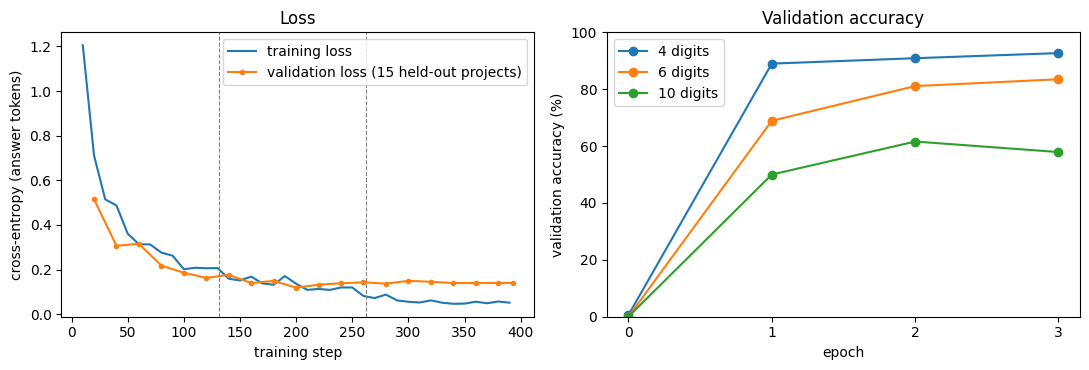

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# 6. Plot and save
import matplotlib.pyplot as plt
from google.colab import files
spe = math.ceil(len(train_data) / BATCH)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(*zip(*TRAIN), label="training loss", lw=1.5)
a1.plot(*zip(*VAL), "o-", ms=3, label="validation loss (15 held-out projects)", lw=1.5)
for e in range(1, EPOCHS):
    a1.axvline(e * spe, ls="--", c="grey", lw=0.8)
a1.set_xlabel("training step"); a1.set_ylabel("cross-entropy (answer tokens)"); a1.legend(); a1.set_title("Loss")
ep = [r["epoch"] for r in EPOCH_ACC]
for k in ("acc@4", "acc@6", "acc@10"):
    a2.plot(ep, [r[k] for r in EPOCH_ACC], "o-", label=k.replace("acc@", "") + " digits")
a2.set_xticks(ep); a2.set_xlabel("epoch"); a2.set_ylabel("validation accuracy (%)"); a2.set_ylim(0, 100)
a2.legend(); a2.set_title("Validation accuracy")
plt.tight_layout(); plt.savefig("validation_curve.png", dpi=200); plt.show()
json.dump({"train_loss": TRAIN, "val_loss": VAL, "val_acc_per_epoch": EPOCH_ACC,
           "settings": dict(model=MODEL_NAME, epochs=EPOCHS, lr=LR, batch=BATCH, lora_r=LORA_R, seed=SEED)},
          open("validation_curve.json", "w"), indent=2)
for f in ("validation_curve.png", "validation_curve.json"):
    files.download(f)